In [1]:
import pandas as pd
import numpy as np
import os
from matplotlib import pyplot as plt

path = "C:/Users/chiar/Desktop/Hackathon/ethnohack/chembl_raw"

def load_dataset():
    csv_path= os.path.join(path,'cox2_cleaned.csv')
    return pd.read_csv(csv_path)


dataset = load_dataset()

In [26]:
df = dataset.drop(["scaffold"],axis=1)


Unparsable SMILES removed: 0
Compounds: 4520 | actives: 2492 (55.1%)

SPLIT: SCAFFOLD   FEATURES: ecfp
train: 3610 | test: 910 | scaffold overlap: 0


Best trial: 18. Best value: 0.788418:  70%|███████   | 21/30 [15:12<06:30, 43.43s/it, 912.08/900 seconds]


Best CV PR-AUC: 0.788 | params: {'n_estimators': 600, 'max_depth': 35, 'min_samples_leaf': 1, 'max_features': 'log2', 'criterion': 'entropy', 'class_weight': 'balanced'}

Prevalence (random-guess PR-AUC): 0.552
PR-AUC   : 0.809
ROC-AUC  : 0.774
MCC      : 0.391
Precision: 0.721
Recall   : 0.745
F1       : 0.733


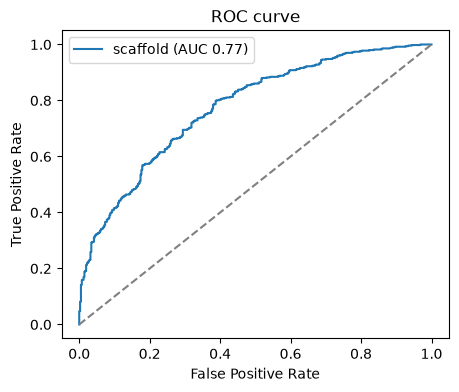


Saved: cox_model.joblib


In [32]:
# ============================================================
# COX / 5-LOX activity model  —  Random Forest
# Input: DataFrame `df` with a canonical SMILES column and a 0/1 activity column
# ============================================================

# ---------- SETTINGS ----------
SMILES_COL = "Smiles"   # name of your SMILES column
LABEL_COL  = "Activity"           # name of your 0/1 column
MODEL_FILE = "cox_model.joblib"   # change per target, e.g. "lox_model.joblib"

SPLIT_MODE = "scaffold"   # "scaffold" = honest, "random" = optimistic, "both" = run both and compare
FEATURES   = "ecfp"       # "ecfp" = 2048-bit ECFP4 (default)
                          # "ecfp_counts" = how OFTEN each substructure occurs, not just yes/no
                          # "ecfp_desc"   = ECFP4 + 10 physicochemical properties
N_TRIALS   = 30           # Optuna trials; lower = faster
TIMEOUT_MIN = 15          # hard stop for the search

# ---------- IMPORTS ----------
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, optuna
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Descriptors, rdMolDescriptors, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.DataStructs import BulkTanimotoSimilarity
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve,
                             matthews_corrcoef, precision_score, recall_score, f1_score)

RDLogger.DisableLog("rdApp.*")                      # silence RDKit warnings
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ============================================================
# 1) CLEAN THE DATA
#    SMILES are already canonical, so we only remove broken rows,
#    compounds with contradictory labels, and duplicates.
# ============================================================
data = df[[SMILES_COL, LABEL_COL]].copy()
data.columns = ["smiles", "label"]
data["label"] = data["label"].astype(int)
data = data.dropna(subset=["smiles"])

ok = data["smiles"].apply(lambda s: Chem.MolFromSmiles(str(s)) is not None)
print("Unparsable SMILES removed:", int((~ok).sum()))
data = data[ok]

# same molecule labelled both 0 and 1 -> we cannot trust it, drop it
conflict = data.groupby("smiles")["label"].nunique()
data = data[~data["smiles"].isin(conflict[conflict > 1].index)]
data = data.drop_duplicates(subset="smiles").reset_index(drop=True)
print(f"Compounds: {len(data)} | actives: {data['label'].sum()} "
      f"({data['label'].mean():.1%})")

# ============================================================
# 2) FEATURES
#    A fingerprint turns a molecule into a fixed-length number vector.
#    ECFP4 = which small substructures are present around each atom.
# ============================================================
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# 10 simple physicochemical properties, only used if FEATURES == "ecfp_desc"
DESC = [Descriptors.MolWt, Descriptors.MolLogP, Descriptors.TPSA,
        Descriptors.NumHDonors, Descriptors.NumHAcceptors,
        Descriptors.NumRotatableBonds, rdMolDescriptors.CalcNumRings,
        rdMolDescriptors.CalcNumAromaticRings, rdMolDescriptors.CalcFractionCSP3,
        Descriptors.HeavyAtomCount]

def featurize(smiles_list, mode=FEATURES):
    """SMILES -> feature matrix. Random forests need no scaling, so we just stack columns."""
    rows = []
    for s in smiles_list:
        mol = Chem.MolFromSmiles(str(s))
        if mode == "ecfp_counts":
            # counts can help when a substructure appearing 3x matters (e.g. polyphenols)
            vec = fp_gen.GetCountFingerprintAsNumPy(mol).astype(np.float32)
        else:
            arr = np.zeros((2048,), dtype=np.uint8)
            DataStructs.ConvertToNumpyArray(fp_gen.GetFingerprint(mol), arr)
            vec = arr.astype(np.float32)
        if mode == "ecfp_desc":
            # adds size/polarity info that fingerprints capture only indirectly
            vec = np.concatenate([vec, np.array([f(mol) for f in DESC], dtype=np.float32)])
        rows.append(vec)
    return np.vstack(rows)

# Murcko scaffold = the ring core of a molecule (side chains stripped off)
def scaffold_of(smi):
    mol = Chem.MolFromSmiles(smi)
    scaf = Chem.MolToSmiles(MurckoScaffold.GetScaffoldForMol(mol))
    return scaf if scaf != "" else "ACYCLIC_" + smi   # ring-free molecules get their own group

data["scaffold"] = data["smiles"].apply(scaffold_of)

# ============================================================
# 3) ONE FULL RUN = split -> tune -> fit -> evaluate
#    Written as a function so we can call it for both split modes.
# ============================================================
def run(split_mode):
    print(f"\n{'='*55}\nSPLIT: {split_mode.upper()}   FEATURES: {FEATURES}\n{'='*55}")

    # ---- 3a) Train/test split -------------------------------------------------
    # RANDOM: like train_test_split. Close analogues of the same compound land in
    #         BOTH sets, so the model can recognise the series instead of the
    #         chemistry -> scores look better than the model really is.
    # SCAFFOLD: all molecules sharing a ring core stay on the same side. This is
    #         closer to your real task (unseen plant metabolites) -> lower but honest.
    if split_mode == "scaffold":
        splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
        tr_i, te_i = next(splitter.split(data, data["label"], groups=data["scaffold"]))
    else:
        splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        tr_i, te_i = next(splitter.split(data, data["label"]))   # 80/20, label-balanced
    train_df, test_df = data.iloc[tr_i], data.iloc[te_i]

    X_tr, y_tr = featurize(train_df["smiles"]), train_df["label"].values
    X_te, y_te = featurize(test_df["smiles"]),  test_df["label"].values
    groups_tr = train_df["scaffold"].values

    print(f"train: {len(train_df)} | test: {len(test_df)} | "
          f"scaffold overlap: {len(set(train_df['scaffold']) & set(test_df['scaffold']))}")

    # ---- 3b) Hyperparameter search -------------------------------------------
    # The inner cross-validation uses the SAME split logic as the outer split,
    # otherwise tuning would be optimistic even with a scaffold test set.
    cv = (StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
          if split_mode == "scaffold"
          else StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
    cv_groups = groups_tr if split_mode == "scaffold" else None

    def make_rf(trial_or_params, from_trial=True):
        """Builds the forest. Works with an Optuna trial or a plain params dict."""
        g = (trial_or_params.suggest_int if from_trial else None)
        p = trial_or_params if not from_trial else None
        return RandomForestClassifier(
            # more trees = more stable, just slower; 300-900 is plenty here
            n_estimators = trial_or_params.suggest_int("n_estimators", 300, 900, step=100)
                           if from_trial else p["n_estimators"],
            # how deep a tree may grow; too deep memorises single compounds
            max_depth = trial_or_params.suggest_int("max_depth", 5, 40)
                        if from_trial else p["max_depth"],
            # bigger leaves = smoother model, less overfitting
            min_samples_leaf = trial_or_params.suggest_int("min_samples_leaf", 1, 10)
                               if from_trial else p["min_samples_leaf"],
            # how many of the 2048 bits each split may look at
            max_features = trial_or_params.suggest_categorical(
                               "max_features", ["sqrt", "log2", 0.1, 0.2])
                           if from_trial else p["max_features"],
            criterion = trial_or_params.suggest_categorical("criterion", ["gini", "entropy"])
                        if from_trial else p["criterion"],
            # "balanced" up-weights the smaller class instead of resampling the data
            class_weight = trial_or_params.suggest_categorical(
                               "class_weight", [None, "balanced"])
                           if from_trial else p["class_weight"],
            n_jobs=-1, random_state=42)

    def objective(trial):
        # average_precision = PR-AUC: the right metric when you care about the actives
        return cross_val_score(make_rf(trial), X_tr, y_tr, groups=cv_groups,
                               cv=cv, scoring="average_precision").mean()

    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT_MIN*60,
                   show_progress_bar=True)
    print("Best CV PR-AUC:", round(study.best_value, 3), "| params:", study.best_params)

    # ---- 3c) Fit the best forest on all training data and test it -------------
    model = make_rf(study.best_params, from_trial=False)
    model.fit(X_tr, y_tr)

    proba = model.predict_proba(X_te)[:, 1]      # probability of being active
    pred  = (proba >= 0.5).astype(int)

    # Prevalence = share of actives. A coin flip would already reach this PR-AUC,
    # so always compare your PR-AUC against this number, not against 0.
    print(f"\nPrevalence (random-guess PR-AUC): {y_te.mean():.3f}")
    print("PR-AUC   :", round(average_precision_score(y_te, proba), 3))
    print("ROC-AUC  :", round(roc_auc_score(y_te, proba), 3))
    print("MCC      :", round(matthews_corrcoef(y_te, pred), 3))
    print("Precision:", round(precision_score(y_te, pred, zero_division=0), 3))
    print("Recall   :", round(recall_score(y_te, pred), 3))
    print("F1       :", round(f1_score(y_te, pred), 3))

    fpr, tpr, _ = roc_curve(y_te, proba)
    plt.plot(fpr, tpr, label=f"{split_mode} (AUC {roc_auc_score(y_te, proba):.2f})")
    return model, train_df, roc_auc_score(y_te, proba)

# ---- run one or both split modes -------------------------------------------
plt.figure(figsize=(5, 4))
if SPLIT_MODE == "both":
    # Nice presentation slide: the gap between the two curves IS the leakage
    # a random split hides. Always report the scaffold number as your result.
    run("random")
    model, train_df, _ = run("scaffold")
else:
    model, train_df, _ = run(SPLIT_MODE)
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curve"); plt.legend(); plt.show()

# ============================================================
# 4) SAVE MODEL + PREDICTION HELPER FOR THE TEAM
# ============================================================
joblib.dump(model, MODEL_FILE)
train_df[["smiles"]].to_csv(MODEL_FILE.replace(".joblib", "_train_smiles.csv"), index=False)

def predict_smiles(smiles_list, model_file=MODEL_FILE, sim_cut=0.5):
    """
    Returns, per molecule:
      proba          - predicted probability of activity
      max_sim_train  - highest Tanimoto similarity to any training compound
      in_domain      - True if max_sim_train >= sim_cut
    Why the similarity? Our model scored AUC ~0.87 on compounds similar to the
    training set but only ~0.65 on dissimilar ones. Plant metabolites are often
    dissimilar, so predictions with a low similarity are much less trustworthy.
    """
    mdl = joblib.load(model_file)
    ref = [fp_gen.GetFingerprint(Chem.MolFromSmiles(s))
           for s in pd.read_csv(model_file.replace(".joblib", "_train_smiles.csv"))["smiles"]]
    out = []
    for s in smiles_list:
        mol = Chem.MolFromSmiles(str(s))
        if mol is None:
            out.append((s, np.nan, np.nan, False)); continue
        sim = max(BulkTanimotoSimilarity(fp_gen.GetFingerprint(mol), ref))
        p = mdl.predict_proba(featurize([s]))[0, 1]
        out.append((s, p, sim, sim >= sim_cut))
    return pd.DataFrame(out, columns=["smiles", "proba", "max_sim_train", "in_domain"])

print(f"\nSaved: {MODEL_FILE}")

In [34]:
import os
print(os.getcwd())
print([f for f in os.listdir() if f.endswith(".joblib")])

c:\Users\chiar\Desktop\Hackathon\ethnohack
['cox_model.joblib']


Explanation stuff: actually the model is just mildly better than baseline, as the signal mostly stems from the structure itself, it basically performs just as well as basic Similarity Search, but might be computationally more efficient

In [35]:
# nearest-active-neighbour baseline
fps_tr_active = [fp for fp, y in zip(fps_tr, y_tr) if y == 1]
sim_to_active = np.array([max(BulkTanimotoSimilarity(fp, fps_tr_active)) for fp in fps_te])

print("Similarity baseline ROC-AUC:", round(roc_auc_score(y_te, sim_to_active), 3))
print("Similarity baseline PR-AUC :", round(average_precision_score(y_te, sim_to_active), 3))
print("Your model      ROC-AUC:", round(roc_auc_score(y_te, proba), 3))
print("Your model      PR-AUC :", round(average_precision_score(y_te, proba), 3))

Similarity baseline ROC-AUC: 0.76
Similarity baseline PR-AUC : 0.792
Your model      ROC-AUC: 0.773
Your model      PR-AUC : 0.807


In [36]:
from scipy.stats import rankdata

combo = (rankdata(proba) + rankdata(sim_to_active)) / 2
print("Combined ROC-AUC:", round(roc_auc_score(y_te, combo), 3))
print("Combined PR-AUC :", round(average_precision_score(y_te, combo), 3))

Combined ROC-AUC: 0.784
Combined PR-AUC : 0.818
